# Is the measured relationality what a non-relational model would produce? → `figure_ks_stats.pdf`

The fitted $\rho$ has a floor problem: fit the relational-bias model to a neuron that is not
relational at all and the optimiser still returns *some* $\rho$. So the question is not
whether $\rho$ is large but whether its **distribution** is one a non-relational neuron could
have produced.

For every neuron and every model, spikes are simulated from that model's own fitted
parameters on that neuron's own trials, and $\rho$ is re-fit to the synthetic spikes. That
gives the distribution of $\rho$ each model predicts, with the real neurons' sampling and
noise built in. The figure is the ECDF of the real $\rho$ against those, one panel per
monkey, and the table is a two-sample KS test of each model against the data.

**Nothing is simulated here.** The synthetic $\rho$ come from
`cache/figures/figure_4/neuron_models/bias_recovery`, keyed by a fingerprint of the fit
each one was drawn from; `synthetic_biases` reuses every entry whose fingerprint matches. If
that cache were missing this cell would refit thousands of neurons.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import common
common.set_style()
import fit_lib
import relationality_lib as rl
import ks_lib as kl

# Legend placement: 'right' (one column beside the panels) or 'below' (three columns under
# them). Each has its own figure size so the panels keep their width.
LEGEND_POSITION = 'right'
FIGSIZE = {'below': (5.2, 2.9), 'right': (6.4, 2.9)}[LEGEND_POSITION]
# Right legend only, in figure fractions (0 = left edge, 1 = right edge). LEGEND_RIGHT_X is
# where the legend's left edge sits; LEGEND_RIGHT_PANELS is where the panels stop. Keep
# LEGEND_RIGHT_X a little above LEGEND_RIGHT_PANELS or the legend overlaps the right panel.
LEGEND_RIGHT_X = 0.78
LEGEND_RIGHT_PANELS = 0.78

OUTPUT = 'figure_ks_stats.pdf'
XLABEL = 'Relationality (r)'

MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)
N_REPS = 5            # synthetic datasets per (neuron, model)
SIM_SEED = 0          # seeds every (neuron, model, rep) draw deterministically
N_JOBS = 6            # joblib workers (never every core). Only used if
                      # the cache is incomplete — a full cache computes nothing. The
                      # first run computes every row: about 2 minutes.

# The two accented models and their colours, kept identical to
# `figure_model_comparison.ipynb` so a reader carries the same association between the two
# figures. Everything else is a light-to-dark grey ramp.
REMAP_MODEL = 'future_field'
REMAP_COLOR = '#c1272d'
SECOND_ACCENT_MODEL = 'basis_function'
SECOND_ACCENT = '#8e3b6b'                  # 'plum' in that notebook's PALETTES
GRAY_LIGHT, GRAY_DARK = 0.78, 0.12
# Dash lengths, all on a common 3-pt gap so only the dash itself varies.
SHORT_DASH, MID_DASH, LONG_DASH = (0.0, (3, 3)), (0.0, (5.0, 3.0)), (0.0, (7.0, 3.0))
DASHES = [LONG_DASH, SHORT_DASH]           # alternating, the default for the grey models

# Every dash decision that is not the alternating default, in one place. The two accents are
# dashed so they stay distinct from the solid data curve. The three greys are given the three
# lengths in order — Weighted Avg. short, Normalization intermediate, Inhibition long — so
# the dash reads as a ramp alongside the grey ramp rather than cutting across it.
DASH_OVERRIDES = {'future_field': LONG_DASH, 'basis_function': SHORT_DASH,
                  'weighted_average': SHORT_DASH, 'normalization': MID_DASH,
                  'inhibition': LONG_DASH}
DATA_COLOR = (0.13, 0.62, 0.31)


In [2]:
cfg = fit_lib.FitConfig()
# `MODELS` is the list of models being *tested*; the metric's own model is the measuring
# instrument and is not one of them, but its fitted parameter still has to be in `summary`
# for `rl.biases` to read — hence the extra entry here and nowhere else. The population is
# the shared criterion's either way: adding a model changes which rows survive, never which
# neurons do.
summary = common.selected_fits(MODELS + (rl.MODEL,))

# The REAL distribution must come from the SAME estimator as the synthetic one, or the KS
# test compares two estimators rather than two hypotheses.
real = rl.biases(summary)
print(f'real bias: median {real['bias'].median():.3f}, n = {len(real)}')


2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
  restricted to 6 models (weighted_average, normalization, inhibition, basis_function, future_field, relational_bias); best_model recomputed within them
  dropped: priority_map, softmax
1339 of 3186 neurons enter the figure (42%)
1339 of 1339 neurons have a fitted bias
real bias: median 0.645, n = 1339


In [3]:
synth = kl.synthetic_biases(summary, MODELS, cfg, n_reps=N_REPS, seed=SIM_SEED,
                            n_jobs=N_JOBS)
print(f'{len(synth)} synthetic neurons')
display(kl.ks_table(real, synth, MODELS, by_subject=True,
                    n_boot=200).round(3))

34425 rows reused from cache, 0 computed
  dropped 38 cached neuron(s) that are not in this population
33475 synthetic neurons in 3s (/Users/nicholaswatters/Desktop/grad_school/research/relational_coding_2026/cache/figures/figure_4/neuron_models/bias_recovery/8ee5ac260b62dffd)
33475 synthetic neurons


,subject,model,label,n,ks,ks_lo,ks_hi,p,median,frac_at_0,frac_at_1
0,Perle,future_field,Future Field,4990,0.043,0.038,0.067,0.084,0.646,0.116,0.002
1,Perle,basis_function,Basis Func.,4990,0.076,0.064,0.097,0.000,0.636,0.102,0.001
2,Perle,normalization,Normalization,4990,0.476,0.446,0.514,0.000,0.151,0.209,0.000
3,Perle,inhibition,Inhibition,4990,0.607,0.578,0.640,0.000,0.210,0.202,0.000
4,Perle,weighted_average,Weighted Avg.,4990,0.714,0.687,0.747,0.000,0.000,0.518,0.000
5,Elgar,future_field,Future Field,1705,0.057,0.044,0.100,0.297,0.534,0.135,0.002
6,Elgar,basis_function,Basis Func.,1705,0.079,0.065,0.123,0.055,0.492,0.112,0.002
7,Elgar,normalization,Normalization,1705,0.460,0.410,0.525,0.000,0.090,0.267,0.000
8,Elgar,inhibition,Inhibition,1705,0.532,0.478,0.590,0.000,0.201,0.197,0.000
9,Elgar,weighted_average,Weighted Avg.,1705,0.653,0.604,0.701,0.000,0.000,0.511,0.001


saved figure_ks_stats.pdf


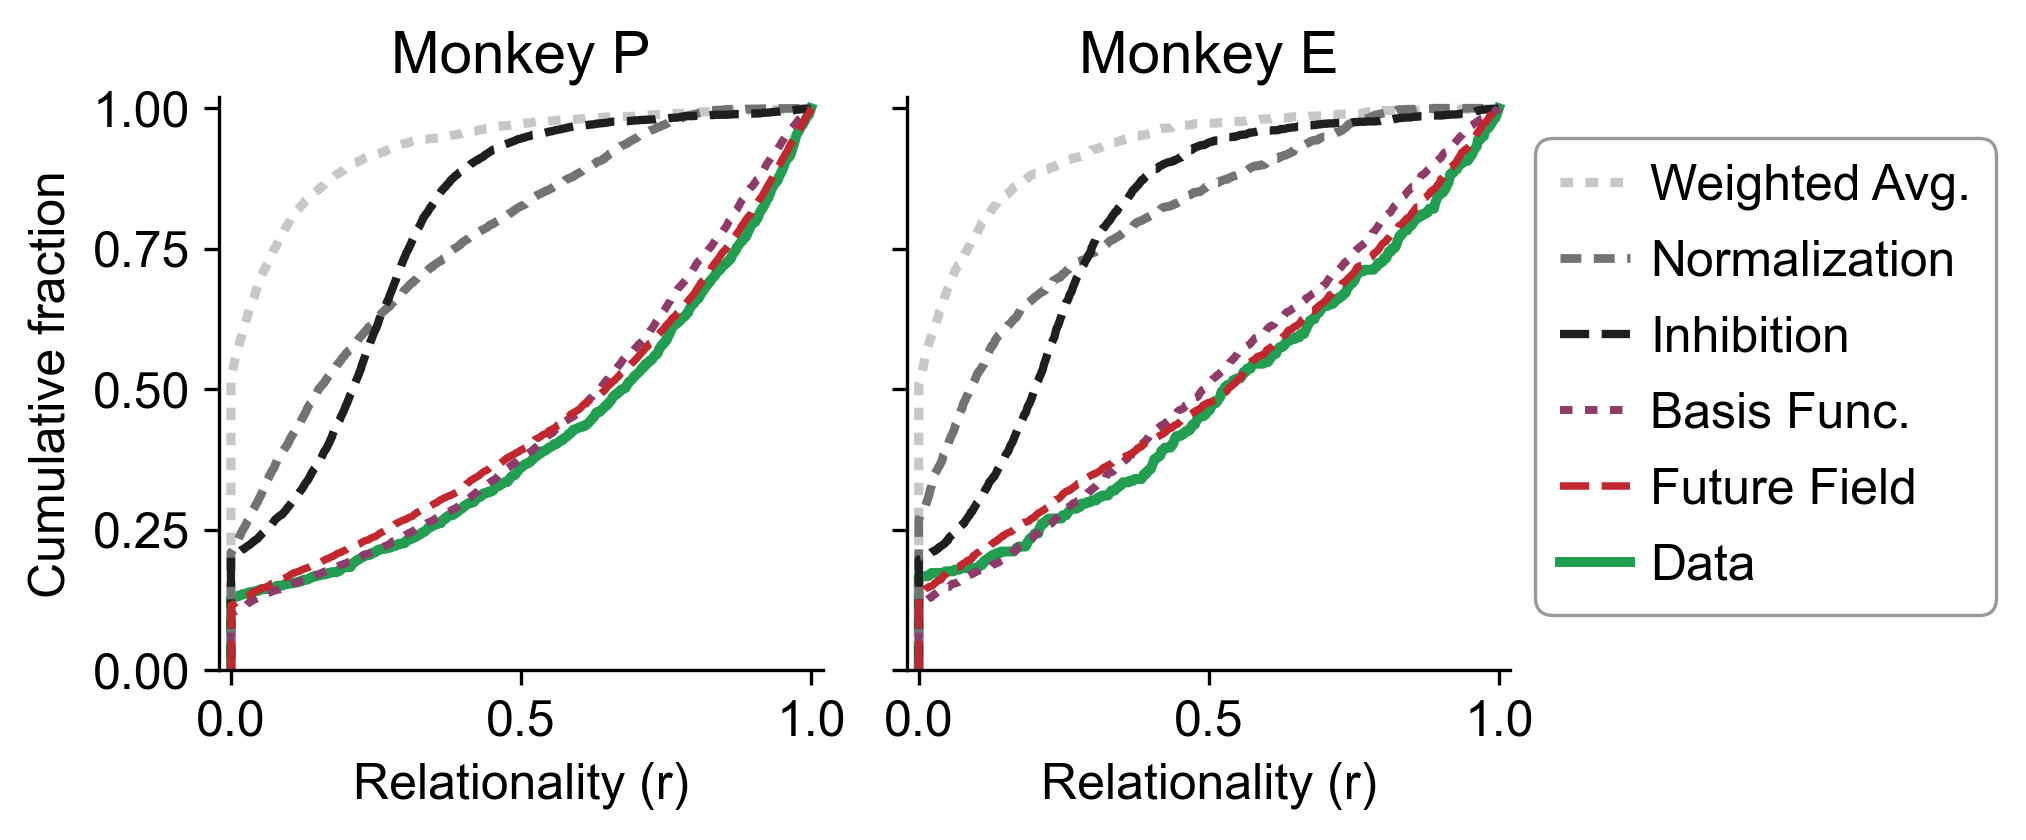

In [4]:
accents = {REMAP_MODEL: REMAP_COLOR, SECOND_ACCENT_MODEL: SECOND_ACCENT}
others = [m for m in MODELS if m not in accents]
colors = {m: str(v) for m, v in zip(others, np.linspace(GRAY_LIGHT, GRAY_DARK, len(others)))}
colors.update({m: c for m, c in accents.items() if m in MODELS})

# Dashes separate curves whose colours are close; DASH_OVERRIDES holds every deviation from
# the alternating default, so the pattern each model gets is readable in one place.
styles = {m: DASHES[i % len(DASHES)] for i, m in enumerate(others)}
styles.update({m: v for m, v in DASH_OVERRIDES.items() if m in MODELS})

LEGEND_PLACEMENT = {
    'below': dict(legend_loc='below', legend_ncol=3, legend_bbox=(0.5, 0.13),
                  legend_margin=0.30),
    'right': dict(legend_loc='right', legend_ncol=1, legend_bbox=(LEGEND_RIGHT_X, 0.55),
                  legend_margin=LEGEND_RIGHT_PANELS),
}

fig, _ = kl.plot_bias_ecdf(
    real, synth, MODELS, colors=colors, styles=styles,
    data_color=DATA_COLOR,
    figsize=FIGSIZE, wspace=0.14,
    xlabel=XLABEL,
    **LEGEND_PLACEMENT[LEGEND_POSITION],
    legend_rounding=0.35, legend_borderpad=0.1,
    legend_labelspacing=0.6, legend_handlelength=1.4, legend_handletextpad=0.4,
    legend_columnspacing=1.2, legend_edgecolor='0.6', legend_lw=0.8,
    lw_step=0.1,)

common.save(fig, OUTPUT)
plt.show()